# Mosquito wingbeat classification replication

## Phase 2 practical work

My aim is to repeat the authors' available evaluation and explain the results. I use their recorded audio, original processing functions and ten released CNN models. A CNN is a neural network that learns patterns by scanning short parts of the input.

There is a limit to what I can reproduce. The ten released models use the older two-convolution MosquitoSong network. The paper's proposed MosquitoSong+ network has three convolution layers. Its matching trained files and complete training code are not available in the linked release. I therefore describe this work as a replication of the released evaluation, not a complete repetition of MosquitoSong+ training.

This notebook has already been run. Its tables, figures and test results are saved below, so it can be read without running the code again. The accompanying Word report explains the method and my interpretation.

## Dataset and sources

I use the Tiny MosquitoSong Dataset released by the authors. It contains 1,324 wingbeat recordings from four mosquito species, with male and female labels for each species. This gives eight classes. Eight environmental recordings and four trap-fan recordings provide the noise. The supplied files used here are 8 kHz, 16-bit audio collected at Mahidol University.

The data comes from the [authors' dataset folder](https://drive.google.com/drive/folders/1jvRfJ4X3UKtyV8regcHRgZLuzwPQWW6N?usp=sharing). The original prediction code is from their [project repository](https://github.com/akaraspt/mosquitosongp), and the trained files are from their [model folder](https://drive.google.com/drive/folders/1TfLHtHpVAfus6msjiDjgdeQHT9m3gnX7?usp=sharing). I retain the authors' source and licence in `sources/`.

Reference paper: Supratak et al. 2024, [MosquitoSong+: A noise-robust deep learning model for mosquito classification from wingbeat sounds](https://doi.org/10.1371/journal.pone.0310121).

## Scope of the replication

| Part of the method | What I use here |
|---|---|
| Input | Raw waveforms from all 1,324 wingbeat files, without removing duplicates or replacing the audio with hand-made features. |
| Audio sections | The authors' 300 ms sections, 150 ms step and random starting shift. |
| Data division | Their original ten-round function and low-cost-microphone test selection. |
| Test sound | Their two-microphone distance, delay, gain, noise selection and subtraction functions, at gains 1, 1.5 and 2. |
| Models | The numerical weights of all ten released two-convolution networks. |
| Training | I do not retrain the models or claim to have reproduced the missing MosquitoSong+ training procedure. |

The released notebook uses TensorFlow 2.4. This run uses TensorFlow 2.16.1 and Keras 3.3.3. I rebuild the inspected layers and load their numerical weights. An independent NumPy calculation checks the network outputs. I select files by exact name because the original substring search can confuse round 1 with round 10. I also reuse predictions when calculating different scores.

The paper describes a simple sum of wingbeat and noise signals. The released test code adds microphone-distance scaling, delays and subtraction. These differences matter when interpreting the scores.

## 1 Setup

The completed outputs are already saved. No installation or local run is needed just to read or submit the notebook.

For an optional rerun, keep `data/`, `models/` and `sources/` beside this file, open it from this folder, then restart the kernel and run all cells. Results are written to `results/`. All implementation code is included here, with no helper Python files. `DATA_ROOT_OVERRIDE` can point to another folder containing the data and sources.

The packages used for the completed run are listed below. This is an optional installation command, not a cell that must run when viewing the notebook.

```text
%pip install tensorflow==2.16.1 keras==3.3.3 numpy==1.26.4 scipy==1.15.3 scikit-learn==1.7.2 pandas==2.2.3 h5py==3.14.0 librosa==0.11.0 matplotlib==3.10.7
```

In [1]:
from pathlib import Path
from collections import Counter
from unittest.mock import patch
import csv
import hashlib
import json
import math
import os
import platform
import random
import re
import time
import unittest
import wave

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import numpy as np
import pandas as pd
import h5py
import librosa
import sklearn
from sklearn import preprocessing
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
import matplotlib.pyplot as plt
from IPython.display import display

tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.keras.utils.set_random_seed(42)

DATA_ROOT_OVERRIDE = None
NOTEBOOK_ROOT = Path.cwd().resolve()
MODEL_DIR = NOTEBOOK_ROOT / 'models'
OUTPUT_DIR = NOTEBOOK_ROOT / 'results'
OUTPUT_DIR.mkdir(exist_ok=True)
LABELS = ('Ae.Aegypti_F', 'Ae.Aegypti_M', 'Ae.Albopictus_F', 'Ae.Albopictus_M',
          'An.Dirus_F', 'An.Dirus_M', 'Cx.Quin_F', 'Cx.Quin_M')

MODEL_HASHES = {'cnn_model_min_val_round1.h5': '6a9434e9a6949c3ca8d12439dcaadfc2dff4d81c6850d8fa29d5b669e3b6e3e0', 'cnn_model_min_val_round10.h5': '1e6c36565735d557ac140ff54a36fb707b069785aa40aea7c44dc66e60006e02', 'cnn_model_min_val_round2.h5': '1bc77a48de67f373bf1b723be990ab1de98d00e4c138b77e89fe580db482705e', 'cnn_model_min_val_round3.h5': '0c4b2d5cabd562c16f2cfc1bf5185fc65c2a7f3c6e8735945d843cebf2620faf', 'cnn_model_min_val_round4.h5': '1a3538db306ee7f7618fc3c60f91bc7863911b371db433137cedc6bb62c51787', 'cnn_model_min_val_round5.h5': 'd8cfc09712c2233786225413b0be5b673d7cbf29dfcbedfe422897010512d7c2', 'cnn_model_min_val_round6.h5': '421f2bcabeb413ce1bd023bf1d7baea836abf15ba83987bd349f6a2a49598969', 'cnn_model_min_val_round7.h5': '9e2dfcfc9b1a28eee4bf044a6bcfb807645ab520ec855d9130c34e9cea58d557', 'cnn_model_min_val_round8.h5': '1460f12734749390366b3c18fb76b4bb3ada3883033df2e122af3f902b0a34a7', 'cnn_model_min_val_round9.h5': 'a6b10245f88d031f63c8c7fbbe96ac32af2b800f454431a3ef3896a43c10e8db'}
EXPECTED_DATA_HASH = 'bf8e5ee3544dc617c6caa053bd3d6e0e44e1764d6350daef4f26fa9f83472141'
EXPECTED_SOURCE_HASH = '55684d682f37077a81709d82523fcac2dfdb72f62200844b9f28fe3946af63e0'


In [2]:
def locate_data(override=None):
    candidate = Path(override).expanduser().resolve() if override is not None else NOTEBOOK_ROOT
    required = ('data/wingbeat', 'data/noise', 'sources/authors_prediction_source.json')
    if all((candidate / name).exists() for name in required):
        return candidate
    raise FileNotFoundError('Open the notebook from its folder, or set DATA_ROOT_OVERRIDE to the folder containing data/ and sources/.')

def check_inputs(root):
    paths = sorted((root / 'data').rglob('*.wav'))
    assert len(paths) == 1336
    entries = [f'{path.relative_to(root).as_posix()}:{hashlib.sha256(path.read_bytes()).hexdigest()}' for path in paths]
    assert hashlib.sha256('\n'.join(entries).encode()).hexdigest() == EXPECTED_DATA_HASH
    assert hashlib.sha256((root / 'sources/authors_prediction_source.json').read_bytes()).hexdigest() == EXPECTED_SOURCE_HASH
    for filename, expected in MODEL_HASHES.items():
        assert hashlib.sha256((MODEL_DIR / filename).read_bytes()).hexdigest() == expected
    for path in paths:
        with wave.open(str(path), 'rb') as audio:
            assert audio.getframerate() == 8000 and audio.getsampwidth() == 2
            assert audio.getcomptype() == 'NONE'
    return len(paths)


DATA_ROOT = locate_data(DATA_ROOT_OVERRIDE)
print('Input files checked:', check_inputs(DATA_ROOT))
print('Run versions:', {'Python': platform.python_version(), 'TensorFlow': tf.__version__,
                        'NumPy': np.__version__, 'librosa': librosa.__version__, 'scikit-learn': sklearn.__version__})


Input files checked: 1336
Run versions: {'Python': '3.12.14', 'TensorFlow': '2.16.1', 'NumPy': '1.26.4', 'librosa': '0.11.0', 'scikit-learn': '1.7.2'}


## 2 Audio sections and data division

I use the following functions from the authors' prediction notebook. Their calculations, random seeds, filename rules and selection limits stay the same. The test sections come only from the low-cost microphone.

The original function shares some audio samples between sets at their boundaries. I keep this behaviour so that I am repeating the released procedure. Fixing it would be a separate experiment. The original training records are unavailable, so I cannot prove that the saved models were trained on exactly these declared training sections.

In [3]:
import re
numbers = re.compile(r'(\d+)')
def numericalSort(value):
    parts = numbers.split(value)
    parts[1::2] = map(int, parts[1::2])
    return parts

def load_data(directory):
    audio_files_name = os.listdir(directory)
    sorted_audio_files_name = sorted(audio_files_name, key=numericalSort)
    return sorted_audio_files_name

def encode_data(dataY):
    le = preprocessing.LabelEncoder()
    Y = le.fit_transform(dataY)
    le_name_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    return Y, le_name_mapping

def recreate_mosquito_filename_without_noise(species,sex, day, lowMic):
    species_sex = (species + '_' + sex).strip()
    day = day.strip()
    isLowMic = lowMic.strip() == "LowMic"
    if isLowMic:
        key = species_sex + '_' + day + '_' + "LowMic"
    else:
        key = species_sex + '_' + day 
    return key

def create_species_dict_without_noise(sorted_audio_files_name):

    keySet = set()
    for file in sorted_audio_files_name:
        row = file.split('_')
        key = recreate_mosquito_filename_without_noise(row[0], row[1], row[2], row[5])
        keySet.add(key)
    keyList = list(keySet)
    empty_species_dict = dict.fromkeys(keyList, 0)
    return empty_species_dict

def count_data(sorted_audio_files_name, dir='./SmallCylinder_big/'):
    count_species = create_species_dict_without_noise(sorted_audio_files_name)
    np.random.seed(42)
    sr = 8000
    target = 2400
    count = 0
    for p in sorted_audio_files_name:
        path = dir + p
        if path.endswith('.wav'):
            row = p.split('_')
            x, sr = librosa.load(path, sr=sr)
            for i in range(0, len(x), int(target / 2)):
                np.random.seed(i)
                shift = np.random.randint(120)
                y = x[i + shift : i + target + shift]
                if (len(y) == target):
                    key = recreate_mosquito_filename_without_noise(row[0], row[1], row[2], row[5])
                    count = count + 1
                    count_species[key] = count_species[key] + 1
    return count_species

count_test_low =  {'Cx.Quin_1F_14D_LowMic': 97,
                   'Ae.Aegypti_1F_21D_LowMic': 19, 
                   'An.Dirus_1M_14D_LowMic': 30,
                   'An.Dirus_1F_14D_LowMic': 34,
                   'Ae.Aegypti_1M_21D_LowMic': 39,
                   'Ae.Albopictus_1F_7D_LowMic': 51,
                   'Ae.Albopictus_1M_7D_LowMic': 46,
                   'Cx.Quin_1M_14D_LowMic': 72,
                   'Ae.Aegypti_1F_5D_LowMic': 64, 
                   'Ae.Albopictus_1F_14D_LowMic': 43,
                   'Ae.Albopictus_1M_14D_LowMic': 57,
                   'Ae.Aegypti_1M_5D_LowMic': 48}

def split_data(sorted_audio_files_name, total_data, fold_round, dir):
    count_species = create_species_dict_without_noise(sorted_audio_files_name)
    count_training_set = create_species_dict_without_noise(sorted_audio_files_name)
    test_index = -1 if fold_round == 9 else fold_round
    low_count = {'Cx.Quin_1F_14D_LowMic': 0,
                   'Ae.Aegypti_1F_21D_LowMic': 0, 
                   'An.Dirus_1F_5D_LowMic': 0,
                   'An.Dirus_1M_5D_LowMic': 0,
                   'An.Dirus_1M_14D_LowMic': 0,
                   'An.Minimus_1F_5D_LowMic': 0,
                   'An.Minimus_1M_5D_LowMic': 0,
                   'An.Dirus_1F_14D_LowMic': 0,
                   'Ae.Aegypti_1M_21D_LowMic': 0,
                   'Cx.Quin_1M_6D_LowMic': 0,
                   'Ae.Albopictus_1F_7D_LowMic': 0,
                   'Ae.Albopictus_1M_7D_LowMic': 0,
                   'Cx.Quin_1F_6D_LowMic': 0,
                   'Cx.Quin_1M_14D_LowMic': 0,
                   'Ae.Aegypti_1F_5D_LowMic': 0, 
                   'Ae.Albopictus_1F_14D_LowMic': 0,
                   'Ae.Albopictus_1M_14D_LowMic': 0,
                   'Ae.Aegypti_1M_5D_LowMic': 0}
    con_count = {'Cx.Quin_1F_14D': 0 ,
                  'Ae.Aegypti_1F_21D': 0,
                  'An.Dirus_1F_5D': 0, 
                  'An.Dirus_1M_5D': 0,
                  'An.Dirus_1M_14D': 0,
                  'An.Minimus_1F_5D': 0,
                  'An.Minimus_1M_5D': 0, 
                  'An.Dirus_1F_14D': 0,
                  'Ae.Aegypti_1M_21D': 0,
                  'Cx.Quin_1M_6D': 0, 
                  'Ae.Albopictus_1F_7D': 0,
                  'Ae.Albopictus_1M_7D':0,
                  'Cx.Quin_1F_6D': 0,
                  'Cx.Quin_1M_14D': 0,
                  'Ae.Aegypti_1F_5D': 0 ,
                  'Ae.Albopictus_1F_14D': 0,
                  'Ae.Albopictus_1M_14D': 0 ,
                  'Ae.Aegypti_1M_5D': 0}
    
    X_train = []
    dataY_train = []
    X_test = []
    dataY_test = []
    X_val = []
    dataY_val = []
    count = 0
    train_count = 0
    val_count = 0
    test_count = 0 
    sr = 8000
    target = 2400

    for p in sorted_audio_files_name:
        path = dir + p
        row = p.split('_')
        if path.endswith('.wav'):

            sex_without_number = row[1][1]
            sex_with_number = row[1]
            sp_gender = row[0] + '_' + sex_without_number
            x, sr = librosa.load(path, sr=sr)

            for i in range(0, len(x), int(target / 2)):
                np.random.seed(i)
                shift = np.random.randint(120)
                y = x[i + shift : i + target + shift]
                if (len(y) == target) and row[0] != "An.Minimus":
                    key = recreate_mosquito_filename_without_noise(row[0], row[1], row[2], row[5])
                    current_frame = count_species[key]
                    count_species[key] = count_species[key] + 1
                    count += 1

                    if (current_frame >= (fold_round * math.floor(total_data[key] * 0.1))) and (current_frame < ((fold_round + 1) * math.floor(total_data[key] * 0.1))):
                        dataY_val.append(sp_gender)
                        X_val.append(y)
                        val_count += 1

                    elif (current_frame >= ((test_index + 1) * math.floor(total_data[key] * 0.1))) and (current_frame < ((test_index + 2) * math.floor(total_data[key] * 0.1))):
                        if (row[5] == "LowMic") and (low_count[key] < count_test_low[key]):
                            low_count[key] += 1
                            dataY_test.append(sp_gender)    
                            X_test.append(y)
                            test_count += 1
                    else:
                        dataY_train.append(sp_gender)
                        X_train.append(y)
                        train_count += 1
    return X_train, X_val, X_test, dataY_train, dataY_val, dataY_test

In [4]:
data_directory = str(DATA_ROOT / 'data/wingbeat') + os.sep
audio_names = load_data(data_directory)
assert len(audio_names) == 1324
data_counts = count_data(audio_names, data_directory)
assert sum(data_counts.values()) == 15421
print('Wingbeat files:', len(audio_names))
print('Candidate short sections:', sum(data_counts.values()))

noise_names = sorted((DATA_ROOT / 'data/noise').glob('*.wav'))
noise_sound = [librosa.load(str(path), mono=False, sr=8000)[0] for path in noise_names]
assert len(noise_sound) == 12
assert all(sound.ndim == 2 and sound.shape[0] == 2 for sound in noise_sound)
print('Two-channel noise recordings:', len(noise_sound))


Wingbeat files: 1324
Candidate short sections: 15421
Two-channel noise recordings: 12


## 3 Noise simulation

The released functions represent two microphones placed 0.3 metres apart. They adjust the wingbeat signal for distance, delay it, select a two-channel noise section and subtract the microphone signals. The gain values are 1, 1.5 and 2.

The first test group is a random mixture of clean and noise-added sections. The code then appends a separate clean group. I keep both groups and record whether each input actually received noise. Here, clean means no extra noise was added by this simulation. It does not mean that the original recording is perfectly free of background sound.

In [5]:
def MultiplyFactorToSound(sound_array, factor):
    factored_array = np.multiply(sound_array, factor)
    return factored_array

def calculate_delay(M1, M2,sr, x ,y):
    c = 343
    xM1_dist = math.hypot(M1[0] - x, M1[1] - y)
    xM2_dist = math.hypot(M2[0] - x, M2[1] - y)
    
    
    xM1_delay_duration = abs(xM1_dist)/ c
    xM2_delay_duration = abs(xM2_dist)/ c
    
    xM1_delay = np.zeros(int(xM1_delay_duration * sr))
    xM2_delay = np.zeros(int(xM2_delay_duration * sr))
    return xM1_dist, xM2_dist, xM1_delay,xM2_delay

def separate_noise_channels(noise_in_two_channels):
    return noise_in_two_channels[1],noise_in_two_channels[0]

def random_shifted_noise_with_seed(noise_1, noise_2, len_mosquito, seed):
    assert len(noise_1) == len(noise_2), "both noise channel must have the same length"
    randomable_range = 0
    endpoint = 0
    randomable_range = len(noise_1) - len_mosquito
    random.seed(seed)
    random_start = int(round(random.uniform(0, randomable_range), 0))
    
    end = random_start + len_mosquito
    random_shifted_noise_1 = noise_1[random_start: end]
    random_shifted_noise_2 = noise_2[random_start: end]

    return random_shifted_noise_1, random_shifted_noise_2

def OverlayAndDelayPerBatchTestSet (np_mosquito, sr, f, seed, is_noise_cancelled):










    length = 0.3
    delta_m = 0.5
    x = ((length * delta_m)) 
    y = 0.05
    M1 = (-(length/2) , 0)
    M2 = (length/2 , 0)


    xM1_dist, xM2_dist, delay_xM1, delay_xM2 = calculate_delay(M1, M2, sr, x , y)


    random.seed(seed)
    randomIndex = random.randint(0,len(noise_sound) - 1)
    mono_M1, mono_M2 = separate_noise_channels(noise_sound[randomIndex])



    random_f = f
    f_M1 = MultiplyFactorToSound(np_mosquito, random_f/xM1_dist)
    f_M2 = MultiplyFactorToSound(np_mosquito, random_f/xM2_dist)



    delay_xM1_np = np.tile(delay_xM1, (f_M1.shape[0],1))
    delay_xM2_np = np.tile(delay_xM2, (f_M2.shape[0],1))
    delayed_mosquito_M1 = np.concatenate((delay_xM1_np,f_M1), axis=1)
    delayed_mosquito_M2 = np.concatenate((delay_xM2_np,f_M2), axis=1)
    delayed_mosquito_M1 = np.delete(delayed_mosquito_M1,np.s_[2400:delayed_mosquito_M1.shape[1]],1)    
    delayed_mosquito_M2 = np.delete(delayed_mosquito_M2,np.s_[2400:delayed_mosquito_M2.shape[1]],1) 
    delayed_cancelled_mosquito_sound = np.subtract(delayed_mosquito_M2, delayed_mosquito_M1)



    noise_1, noise_2 = random_shifted_noise_with_seed(mono_M1,mono_M2, 2400, seed)
    overlay_M1 = np.add(delayed_mosquito_M1, noise_1.reshape(1,delayed_mosquito_M1.shape[1]))
    overlay_M2 = np.add(delayed_mosquito_M2, noise_2.reshape(1,delayed_mosquito_M2.shape[1]))
    denoised_sound = np.subtract(overlay_M2, overlay_M1)
    if is_noise_cancelled:
        sample_list = [delayed_cancelled_mosquito_sound, denoised_sound]
    elif is_noise_cancelled == False:
        sample_list = [delayed_mosquito_M2, overlay_M2]
    return random.choice(sample_list)

def DelayTestSet (np_mosquito, sr, f, is_noise_cancelled):











    length = 0.3
    delta_m = 0.5
    x = ((length * delta_m)) 
    y = 0.05
    M1 = (-(length/2) , 0)
    M2 = (length/2 , 0)
    xM1_dist, xM2_dist, delay_xM1, delay_xM2 = calculate_delay(M1, M2, sr, x , y)


    f_M1 = MultiplyFactorToSound(np_mosquito, f/xM1_dist)
    f_M2 = MultiplyFactorToSound(np_mosquito, f/xM2_dist)


    delay_xM1_np = np.tile(delay_xM1, (f_M1.shape[0],1))
    delay_xM2_np = np.tile(delay_xM2, (f_M2.shape[0],1))
    delayed_mosquito_M1 = np.concatenate((delay_xM1_np,f_M1), axis=1)
    delayed_mosquito_M2 = np.concatenate((delay_xM2_np,f_M2), axis=1)
    delayed_mosquito_M1 = np.delete(delayed_mosquito_M1,np.s_[2400:delayed_mosquito_M1.shape[1]],1)    
    delayed_mosquito_M2 = np.delete(delayed_mosquito_M2,np.s_[2400:delayed_mosquito_M2.shape[1]],1) 
    denoised_sound = np.subtract(delayed_mosquito_M2, delayed_mosquito_M1)
    if is_noise_cancelled:
        return denoised_sound
    elif is_noise_cancelled == False:
        return delayed_mosquito_M2

def create_validation_or_test_set(dataX, seed_increment, is_noise_cancelled):
    f1 = []
    f15 = []
    f2 = []
    for idx, val in enumerate(dataX):

        seed = seed_increment + idx
        f1.append(OverlayAndDelayPerBatchTestSet(np.array(dataX[idx]).reshape(1, np.array(dataX[idx]).shape[0]), 8000,1, seed, is_noise_cancelled))    
        f15.append(OverlayAndDelayPerBatchTestSet(np.array(dataX[idx]).reshape(1, np.array(dataX[idx]).shape[0]), 8000,1.5,seed, is_noise_cancelled))    
        f2.append(OverlayAndDelayPerBatchTestSet(np.array(dataX[idx]).reshape(1, np.array(dataX[idx]).shape[0]), 8000,2,seed, is_noise_cancelled))    

    totalX_test = np.concatenate((f1, f15, f2))
    np.array(totalX_test).shape

    f1 = np.array(f1)
    f15 = np.array(f15)
    f2 = np.array(f2)
    f1 = np.array(f1).reshape(f1.shape[0], f1.shape[2], f1.shape[1])
    f15 = np.array(f15).reshape(f15.shape[0], f15.shape[2], f15.shape[1])
    f2 = np.array(f2).reshape(f2.shape[0], f2.shape[2], f2.shape[1])
    totalX_test = np.array(totalX_test).reshape(totalX_test.shape[0], totalX_test.shape[2], totalX_test.shape[1])
    return f1, f15, f2, totalX_test

def create_test_set_without_noise(X_test, seed_increment, is_noise_cancelled):
    f1_no_noise = []
    f15_no_noise = []
    f2_no_noise = []
    for idx, val in enumerate(X_test):

        val = np.array(val)
        f1_no_noise.append(DelayTestSet(np.array(val).reshape(1, np.array(val).shape[0]), 8000,1, is_noise_cancelled))    
        f15_no_noise.append(DelayTestSet(np.array(val).reshape(1, np.array(val).shape[0]), 8000,1.5, is_noise_cancelled))    
        f2_no_noise.append(DelayTestSet(np.array(val).reshape(1, np.array(val).shape[0]), 8000,2, is_noise_cancelled))    

    totalX_test_no_noise = np.concatenate((f1_no_noise, f15_no_noise, f2_no_noise))
    np.array(totalX_test_no_noise).shape

    f1_no_noise = np.array(f1_no_noise)
    f15_no_noise = np.array(f15_no_noise)
    f2_no_noise = np.array(f2_no_noise)

    f1_no_noise = np.array(f1_no_noise).reshape(f1_no_noise.shape[0], f1_no_noise.shape[2], f1_no_noise.shape[1])
    f15_no_noise = np.array(f15_no_noise).reshape(f15_no_noise.shape[0], f15_no_noise.shape[2], f15_no_noise.shape[1])
    f2_no_noise = np.array(f2_no_noise).reshape(f2_no_noise.shape[0], f2_no_noise.shape[2], f2_no_noise.shape[1])
    totalX_test_no_noise = np.array(totalX_test_no_noise).reshape(totalX_test_no_noise.shape[0], totalX_test_no_noise.shape[2], totalX_test_no_noise.shape[1])
    return f1_no_noise, f15_no_noise,f2_no_noise, totalX_test_no_noise

## 4 Released networks

The ten saved networks each have two convolution layers with filter widths of 350 and 100. Pooling layers reduce nearby values, and fully connected layers combine the learned patterns. The last layer gives probabilities for the eight labels.

The loader checks the expected settings and reads numerical weights. It creates only the inspected standard layers instead of executing a downloaded model definition. I do not change or retrain those weights. Dropout, which leaves out some values during training, is switched off for evaluation.

In [6]:
def inspect_and_build_model(path):
    with h5py.File(path, 'r') as saved:
        config = json.loads(saved.attrs['model_config'])
        layers = config['config']['layers']
        expected_types = ['InputLayer', 'Conv1D', 'MaxPooling1D', 'Conv1D', 'MaxPooling1D',
                          'Flatten', 'Dropout', 'Dense', 'Dense', 'Dense']
        if [layer['class_name'] for layer in layers] != expected_types:
            raise ValueError('This file does not have the inspected released architecture.')
        input_config = layers[0]['config']
        assert input_config['batch_input_shape'][1:] == [2400, 1]
        conv = [layer['config'] for layer in layers if layer['class_name'] == 'Conv1D']
        assert [(layer['filters'], layer['kernel_size'], layer['strides'], layer['padding'], layer['activation']) for layer in conv] == [
            (32, [350], [4], 'valid', 'relu'), (32, [100], [1], 'valid', 'relu')]
        pools = [layer['config'] for layer in layers if layer['class_name'] == 'MaxPooling1D']
        assert [(layer['pool_size'], layer['strides'], layer['padding']) for layer in pools] == [([4], [4], 'valid'), ([3], [3], 'valid')]
        dense = [layer['config'] for layer in layers if layer['class_name'] == 'Dense']
        assert [(layer['units'], layer['activation']) for layer in dense] == [(256, 'relu'), (128, 'relu'), (8, 'softmax')]
        assert layers[6]['config']['rate'] == 0.5
        assert all(layer['config'].get('data_format', 'channels_last') == 'channels_last' for layer in layers)
        network = tf.keras.Sequential([
            tf.keras.Input(shape=(2400, 1)),
            tf.keras.layers.Conv1D(32, 350, strides=4, padding='valid', activation='relu'),
            tf.keras.layers.MaxPooling1D(4, strides=4),
            tf.keras.layers.Conv1D(32, 100, padding='valid', activation='relu'),
            tf.keras.layers.MaxPooling1D(3, strides=3),
            tf.keras.layers.Flatten(), tf.keras.layers.Dropout(0.5),
            tf.keras.layers.Dense(256, activation='relu'), tf.keras.layers.Dense(128, activation='relu'),
            tf.keras.layers.Dense(8, activation='softmax')])
        reference_layers = []
        for settings, layer in zip(layers[1:], network.layers):
            values = []
            if settings['class_name'] in ('Conv1D', 'Dense'):
                assert settings['config'].get('use_bias', True)
                group = saved['model_weights'][settings['config']['name']]
                weight_names = [name.decode() if isinstance(name, bytes) else str(name) for name in group.attrs['weight_names']]
                values = [np.asarray(group[name]) for name in weight_names]
                assert len(values) == 2 and all(np.isfinite(value).all() for value in values)
                assert [value.shape for value in values] == [value.shape for value in layer.get_weights()]
                layer.set_weights(values)
            reference_layers.append((settings['class_name'], settings['config'], values))
        assert network.count_params() == 221576
        return network, reference_layers


def numpy_forward(waveforms, layers):
    values = np.asarray(waveforms, dtype=np.float32)
    for kind, settings, weights in layers:
        if kind == 'Conv1D':
            kernel, bias = weights
            width, stride = settings['kernel_size'][0], settings['strides'][0]
            sections = np.lib.stride_tricks.sliding_window_view(values, width, axis=1)[:, ::stride]
            sections = sections.transpose(0, 1, 3, 2)
            values = sections.reshape(-1, width * kernel.shape[1]) @ kernel.reshape(-1, kernel.shape[2]) + bias
            values = values.reshape(sections.shape[0], sections.shape[1], kernel.shape[2])
            values = np.maximum(values, 0)
        elif kind == 'MaxPooling1D':
            sections = np.lib.stride_tricks.sliding_window_view(values, settings['pool_size'][0], axis=1)
            values = sections[:, ::settings['strides'][0]].max(axis=-1)
        elif kind == 'Flatten':
            values = values.reshape(len(values), -1)
        elif kind == 'Dropout':
            pass
        elif kind == 'Dense':
            values = values @ weights[0] + weights[1]
            if settings['activation'] == 'relu':
                values = np.maximum(values, 0)
            else:
                values = np.exp(values - values.max(axis=1, keepdims=True))
                values /= values.sum(axis=1, keepdims=True)
    return values


architecture_rows = []
for round_number in range(1, 11):
    path = MODEL_DIR / f'cnn_model_min_val_round{round_number}.h5'
    network, reference = inspect_and_build_model(path)
    architecture_rows.append({'Round': round_number, 'Convolution layers': 2,
                              'Filter widths': '350, 100', 'Parameters': network.count_params()})
display(pd.DataFrame(architecture_rows))


,Round,Convolution layers,Filter widths,Parameters
0,1,2,"350, 100",221576
1,2,2,"350, 100",221576
2,3,2,"350, 100",221576
3,4,2,"350, 100",221576
4,5,2,"350, 100",221576
5,6,2,"350, 100",221576
6,7,2,"350, 100",221576
7,8,2,"350, 100",221576
8,9,2,"350, 100",221576
9,10,2,"350, 100",221576


## 5 Evaluate the ten rounds

Each round contains 600 selected test sections. Three gain values and two test groups produce 3,600 inputs per round. The complete run therefore saves 36,000 predictions. Several inputs are different versions of the same original section, so they are not independent recordings.

Each round uses its corresponding released model. I keep the authors' label order and check that all declared sets contain the same eight labels. I save the clean-or-noisy choice with every prediction.

In [7]:
def prediction_batch(network, inputs, batch_size=32):
    outputs = [network(np.asarray(inputs[start:start+batch_size], dtype=np.float32), training=False).numpy()
               for start in range(0, len(inputs), batch_size)]
    probabilities = np.concatenate(outputs)
    assert probabilities.shape == (len(inputs), 8)
    assert np.isfinite(probabilities).all()
    np.testing.assert_allclose(probabilities.sum(axis=1), 1, rtol=1e-5, atol=1e-5)
    return probabilities


def build_test_inputs(test_sections):
    selected = []
    original_choice = random.choice
    def tracked_choice(options):
        choice = original_choice(options)
        selected.append(0 if choice is options[0] else 1)
        return choice
    with patch.object(random, 'choice', tracked_choice):
        mixed_groups = create_validation_or_test_set(test_sections, 0, is_noise_cancelled=True)
    clean_groups = create_test_set_without_noise(test_sections, 0, is_noise_cancelled=True)
    mixed_noise_flags = np.asarray(selected).reshape(len(test_sections), 3).T.reshape(-1)
    all_inputs = np.concatenate((mixed_groups[3], clean_groups[3]))
    noise_flags = np.concatenate((mixed_noise_flags, np.zeros(3*len(test_sections), dtype=int)))
    assert all_inputs.shape == (6*len(test_sections), 2400, 1)
    return all_inputs, noise_flags


fold_results, prediction_rows, parity_rows = [], [], []
for fold in range(10):
    started = time.perf_counter()
    X_train, X_val, X_test, train_labels, validation_labels, test_labels = split_data(audio_names, data_counts, fold, data_directory)
    assert (len(X_train), len(X_val), len(X_test)) == (12359, 1531, 600)
    y_train, train_map = encode_data(train_labels)
    y_val, validation_map = encode_data(validation_labels)
    y_test, test_map = encode_data(test_labels)
    assert train_map == validation_map == test_map == {label: index for index, label in enumerate(LABELS)}
    test_inputs, noise_flags = build_test_inputs(X_test)
    true_labels = np.tile(np.asarray(test_labels), 6)
    model, reference_layers = inspect_and_build_model(MODEL_DIR / f'cnn_model_min_val_round{fold+1}.h5')
    comparison_indices = sorted(set(list(range(0, 3600, 600)) +
                                    [int(np.flatnonzero(true_labels == label)[0]) for label in LABELS]))
    comparison_inputs = test_inputs[comparison_indices]
    tensorflow_values = model(np.asarray(comparison_inputs, dtype=np.float32), training=False).numpy()
    numpy_values = numpy_forward(comparison_inputs, reference_layers)
    np.testing.assert_allclose(tensorflow_values, numpy_values, rtol=1e-4, atol=2e-5)
    assert np.array_equal(tensorflow_values.argmax(axis=1), numpy_values.argmax(axis=1))
    parity_rows.append({'round': fold+1, 'inputs_checked': len(comparison_indices),
                        'max_probability_difference': float(np.abs(tensorflow_values-numpy_values).max())})
    probabilities = prediction_batch(model, test_inputs)
    predictions = np.asarray(LABELS)[probabilities.argmax(axis=1)]
    fold_results.append({'round': fold+1, 'train_sections': len(X_train), 'validation_sections': len(X_val),
                         'test_sections': len(X_test), 'evaluated_inputs': len(test_inputs),
                         'accuracy': float(accuracy_score(true_labels, predictions)),
                         'macro_f1': float(f1_score(true_labels, predictions, labels=list(LABELS), average='macro', zero_division=0)),
                         'noise_added': int(noise_flags.sum()), 'clean_inputs': int((noise_flags == 0).sum())})
    for index, (truth, predicted, noise_added) in enumerate(zip(true_labels, predictions, noise_flags)):
        group = index // 600
        prediction_rows.append({'round': fold+1, 'section_index': index % 600, 'gain': (1, 1.5, 2)[group % 3],
                                'test_group': 'mixed' if group < 3 else 'clean', 'noise_added': int(noise_added),
                                'true_label': str(truth), 'prediction': str(predicted)})
    print('Round', fold+1, 'accuracy', round(fold_results[-1]['accuracy'], 4),
          'macro-F1', round(fold_results[-1]['macro_f1'], 4), flush=True)
    del X_train, X_val, X_test, test_inputs, probabilities, model, reference_layers
    tf.keras.backend.clear_session()

prediction_table = pd.DataFrame(prediction_rows)
fold_table = pd.DataFrame(fold_results)
prediction_table.to_csv(OUTPUT_DIR / 'predictions.csv', index=False)
fold_table.to_csv(OUTPUT_DIR / 'fold_results.csv', index=False)
display(fold_table.round(4))


Round 1 accuracy 0.8786 macro-F1 0.8594


Round 2 accuracy 0.9414 macro-F1 0.9364


Round 3 accuracy 0.9164 macro-F1 0.9018


Round 4 accuracy 0.9419 macro-F1 0.9409


Round 5 accuracy 0.9278 macro-F1 0.9183


...

Round 7 accuracy 0.9472 macro-F1 0.9394


Round 8 accuracy 0.9422 macro-F1 0.9247


Round 9 accuracy 0.8953 macro-F1 0.89


Round 10 accuracy 0.9064 macro-F1 0.8994


,round,train_sections,validation_sections,test_sections,evaluated_inputs,accuracy,macro_f1,noise_added,clean_inputs
0,1,12359,1531,600,3600,0.8786,0.8594,873,2727
1,2,12359,1531,600,3600,0.9414,0.9364,873,2727
2,3,12359,1531,600,3600,0.9164,0.9018,873,2727
3,4,12359,1531,600,3600,0.9419,0.9409,873,2727
4,5,12359,1531,600,3600,0.9278,0.9183,873,2727
5,6,12359,1531,600,3600,0.9608,0.9552,873,2727
6,7,12359,1531,600,3600,0.9472,0.9394,873,2727
7,8,12359,1531,600,3600,0.9422,0.9247,873,2727
8,9,12359,1531,600,3600,0.8953,0.8900,873,2727
9,10,12359,1531,600,3600,0.9064,0.8994,873,2727


## 6 Results

Accuracy is the fraction of correct predictions. Macro-F1 calculates F1 for each label and averages the eight values equally. The confusion matrix shows where one label is mistaken for another. All figures below come from this notebook's completed run.

The authors round each round's scores to three decimal places before averaging. I show that result separately from the unrounded average and the score calculated from all predictions together. I also separate inputs that actually received noise from those that did not.

,gain,inputs,pooled_accuracy,pooled_macro_f1,mean_round_accuracy,mean_round_macro_f1,released_report_accuracy,released_report_macro_f1
0,1,12000,0.9216,0.9105,0.9216,0.9110,0.9215,0.9111
1,1.5,12000,0.9271,0.9176,0.9271,0.9178,0.9272,0.9177
2,2,12000,0.9288,0.9210,0.9288,0.9210,0.9287,0.9210
3,all,36000,0.9258,0.9164,0.9258,0.9166,0.9257,0.9164


,noise_added,inputs,accuracy,macro_f1
0,0,27270,0.9338,0.9260
1,1,8730,0.9008,0.8872


,condition,inputs,accuracy,macro_f1
0,clean,8730,0.9371,0.9270
1,noisy,8730,0.9008,0.8872


,precision,recall,f1-score,support
Ae.Aegypti_F,0.9324,0.9227,0.9275,4980.0000
Ae.Aegypti_M,0.9018,0.8446,0.8723,5220.0000
Ae.Albopictus_F,0.9532,0.9200,0.9363,5640.0000
Ae.Albopictus_M,0.9645,0.9544,0.9594,6180.0000
An.Dirus_F,0.8630,0.9294,0.8950,2040.0000
An.Dirus_M,0.7947,0.9289,0.8566,1800.0000
Cx.Quin_F,0.9494,0.9768,0.9629,5820.0000
Cx.Quin_M,0.9193,0.9225,0.9209,4320.0000
accuracy,0.9258,0.9258,0.9258,0.9258
macro avg,0.9098,0.9249,0.9164,36000.0000


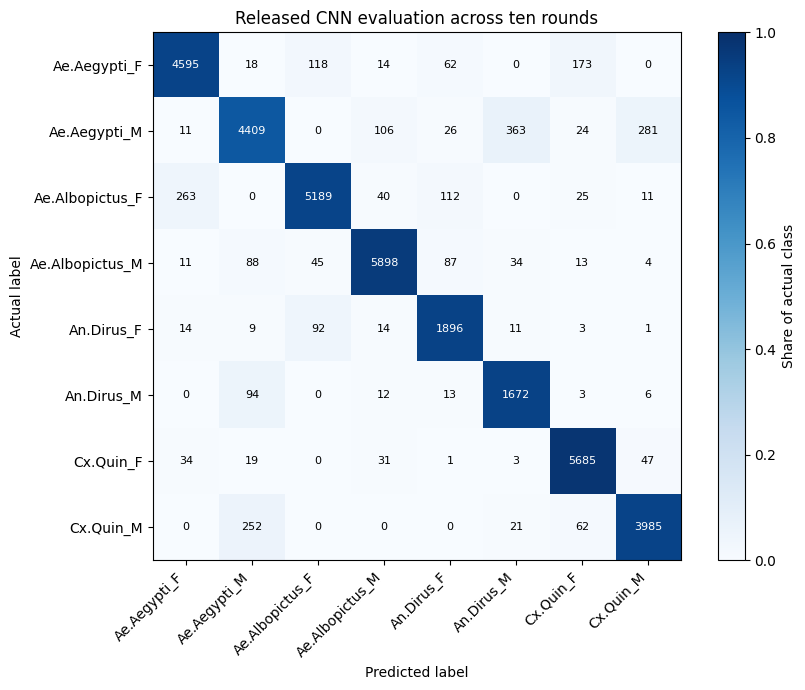

In [8]:
def calculate_scores(frame):
    return {'inputs': len(frame), 'accuracy': float(accuracy_score(frame.true_label, frame.prediction)),
            'macro_f1': float(f1_score(frame.true_label, frame.prediction, labels=list(LABELS), average='macro', zero_division=0))}


summary_rows = []
for gain in (1, 1.5, 2, 'all'):
    selected = prediction_table if gain == 'all' else prediction_table[prediction_table.gain == gain]
    pooled = calculate_scores(selected)
    per_round = [calculate_scores(frame) for _, frame in selected.groupby('round')]
    summary_rows.append({'gain': gain, 'inputs': pooled['inputs'], 'pooled_accuracy': pooled['accuracy'],
                         'pooled_macro_f1': pooled['macro_f1'],
                         'mean_round_accuracy': float(np.mean([row['accuracy'] for row in per_round])),
                         'mean_round_macro_f1': float(np.mean([row['macro_f1'] for row in per_round])),
                         'released_report_accuracy': float(np.mean([np.round(row['accuracy'], 3) for row in per_round])),
                         'released_report_macro_f1': float(np.mean([np.round(row['macro_f1'], 3) for row in per_round]))})
summary_table = pd.DataFrame(summary_rows)
display(summary_table.round(4))
summary_table.to_csv(OUTPUT_DIR / 'score_summary.csv', index=False)

noise_condition_rows = [dict(noise_added=int(flag), **calculate_scores(frame))
                        for flag, frame in prediction_table.groupby('noise_added')]
display(pd.DataFrame(noise_condition_rows).round(4))

paired = prediction_table[prediction_table.noise_added == 1].merge(
    prediction_table[prediction_table.test_group == 'clean'],
    on=['round', 'section_index', 'gain'], suffixes=('_noisy', '_clean'), validate='one_to_one')
assert len(paired) == int(prediction_table.noise_added.sum())
assert (paired.true_label_noisy == paired.true_label_clean).all()
paired_scores = []
for condition in ('clean', 'noisy'):
    frame = paired[[f'true_label_{condition}', f'prediction_{condition}']].rename(
        columns={f'true_label_{condition}': 'true_label', f'prediction_{condition}': 'prediction'})
    paired_scores.append(dict(condition=condition, **calculate_scores(frame)))
display(pd.DataFrame(paired_scores).round(4))

report = classification_report(prediction_table.true_label, prediction_table.prediction,
                               labels=list(LABELS), output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(4))
matrix = confusion_matrix(prediction_table.true_label, prediction_table.prediction, labels=list(LABELS))
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(matrix / matrix.sum(axis=1, keepdims=True), vmin=0, vmax=1, cmap='Blues')
ax.set(xticks=range(8), yticks=range(8), xticklabels=LABELS, yticklabels=LABELS,
       xlabel='Predicted label', ylabel='Actual label', title='Released CNN evaluation across ten rounds')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
for row in range(8):
    for column in range(8):
        ax.text(column, row, str(matrix[row, column]), ha='center', va='center', fontsize=8,
                color='white' if matrix[row, column] / matrix[row].sum() > 0.5 else 'black')
fig.colorbar(im, ax=ax, label='Share of actual class')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=160)
plt.show()


## 7 Proposed architecture in the paper

The paper's Figure 2 shows three convolution widths of 100, 64 and 64, with 32, 32 and 64 filters. Their steps are 4, 4 and 3. Pooling, 50% dropout, two fully connected layers of 256 and 128 units, and an eight-class output follow.

I build this layout only to inspect its dimensions. It has not been trained and has no accuracy result here. It uses valid padding, following the older released model. Since the paper does not explicitly specify padding for the new layers, this is an assumption.

The paper describes Adam with learning rate 0.0001, weighted cross-entropy, 1,000 epochs and validation-based selection. During training, 90% of examples receive environmental noise and 10% remain clean. It also describes gain variation, Gaussian noise, time shifts and amplitude changes. Exact class weights, batch size, augmentation order and complete training code are not supplied. I have not guessed these missing details.

In [9]:
proposed_model = tf.keras.Sequential([
    tf.keras.Input(shape=(2400, 1)),
    tf.keras.layers.Conv1D(32, 100, strides=4, padding='valid', activation='relu'),
    tf.keras.layers.Conv1D(32, 64, strides=4, padding='valid', activation='relu'),
    tf.keras.layers.Conv1D(64, 64, strides=3, padding='valid', activation='relu'),
    tf.keras.layers.MaxPooling1D(3, strides=3),
    tf.keras.layers.Flatten(), tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(256, activation='relu'), tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(8, activation='softmax')])
assert proposed_model.count_params() == 348808
assert proposed_model(np.zeros((1, 2400, 1), dtype=np.float32), training=False).shape == (1, 8)
proposed_model.summary()
print('Layout check only. This model has not been trained and has no reported accuracy here.')


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 576, 32)        │         3,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 129, 32)        │        65,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 22, 64)         │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       114,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 348,808 (1.33 MB)

 Trainable params: 348,808 (1.33 MB)

 Non-trainable params: 0 (0.00 B)

Layout check only. This model has not been trained and has no reported accuracy here.


## 8 My interpretation

The pooled result is 92.58% accuracy and 0.9164 macro-F1. Following the authors' rounding and averaging rule gives 92.57% and 0.9164. The paper's Experiment 1 reports 91.8% accuracy and 0.911 macro-F1 for MosquitoSong+. The similar numbers do not prove replication because my run evaluates the released older networks under the released microphone simulation.

Of the 36,000 inputs, 27,270 receive no extra noise and 8,730 receive noise. This means that 75.75% of the combined inputs are clean under this definition. Their accuracy is 93.38%, compared with 90.08% for the noise-added inputs. The matched table compares each noise-added section with its own clean counterpart at the same round and gain. The matched clean accuracy is 93.71%. This is a more direct comparison than comparing two different groups of sections, but it still applies only to the supplied simulation.

Accuracy increases from 92.16% at gain 1 to 92.88% at gain 2. The difference is about 0.72 percentage points. I treat this as a descriptive result, not a statistically proven improvement. Male Aedes aegypti is often confused with male Anopheles dirus and male Culex quinquefasciatus. The matrix shows those mistakes but does not establish their biological cause.

Shared samples at set boundaries could make evaluation easier if the same division was used during training. I cannot establish the models' historical training division or measure how much any published score was affected. The same sections also appear at several gains and in both test groups, so 36,000 predictions do not mean 36,000 independent observations.

I use the released WAV amplitudes as they are. The paper describes dataset-wide scaling, but its original scaling values are not supplied. Differences in preprocessing history, software, models and test construction prevent me from attributing the score difference to one cause.

This is my first project involving audio processing with deep learning. I had to distinguish an audio recording from the shorter sections that the network actually receives. I also learned to check what a saved model contains before comparing its score with a paper. My conclusion is that the available models work well under this released test procedure, while a complete repeat of MosquitoSong+ still needs the correct trained files and full training details.

In [10]:
pooled = calculate_scores(prediction_table)
result = {
    'scope': 'Released older MosquitoSong CNN evaluation, not full MosquitoSong+ replication',
    'trained_here': False, 'released_models_checked': 10, 'convolution_layers_in_released_models': 2,
    'input_files': 1324, 'noise_files': 12, 'rounds': 10, 'predictions': len(prediction_table),
    'pooled': pooled, 'score_summary': summary_rows, 'folds': fold_results,
    'noise_condition_scores': noise_condition_rows,
    'matched_clean_and_noisy_scores': paired_scores,
    'noise_added_inputs': int(prediction_table.noise_added.sum()),
    'clean_inputs': int((prediction_table.noise_added == 0).sum()),
    'numpy_tensorflow_checks': parity_rows,
    'paper_reference': {'accuracy': 0.918, 'macro_f1': 0.911, 'directly_comparable': False},
    'environment': {'python': platform.python_version(), 'tensorflow': tf.__version__, 'numpy': np.__version__,
                    'librosa': librosa.__version__, 'sklearn': sklearn.__version__},
    'prediction_file_sha256': hashlib.sha256((OUTPUT_DIR / 'predictions.csv').read_bytes()).hexdigest(),
    'model_file_sha256': MODEL_HASHES,
}
(OUTPUT_DIR / 'replication_results.json').write_text(json.dumps(result, indent=2), encoding='utf-8')
print('Released older model accuracy:', round(pooled['accuracy'], 4))
print('Released older model macro-F1:', round(pooled['macro_f1'], 4))
print('Inputs actually given added noise:', result['noise_added_inputs'])
print('Inputs without added noise:', result['clean_inputs'])
print('The three-layer MosquitoSong+ result remains unreplicated.')


Released older model accuracy: 0.9258
Released older model macro-F1: 0.9164
Inputs actually given added noise: 8730
Inputs without added noise: 27270
The three-layer MosquitoSong+ result remains unreplicated.


## 9 Checks

The eight tests below check the released models, split sizes, label coverage, clean/noisy pairing, saved scores, the authors' rounding rule and an independent calculation of the network outputs. The untrained proposed layout is checked separately so it is not mistaken for a completed training experiment.

In [11]:
class ReplicationTests(unittest.TestCase):
    def test_all_ten_models_are_the_released_older_network(self):
        self.assertEqual(len(architecture_rows), 10)
        self.assertTrue(all(row['Convolution layers'] == 2 and row['Parameters'] == 221576 for row in architecture_rows))

    def test_original_split_counts_are_kept(self):
        self.assertEqual(len(fold_results), 10)
        self.assertTrue(all((row['train_sections'], row['validation_sections'], row['test_sections']) == (12359, 1531, 600) for row in fold_results))

    def test_complete_prediction_coverage_and_labels(self):
        self.assertEqual(len(prediction_table), 36000)
        self.assertEqual(set(prediction_table.true_label), set(LABELS))
        self.assertEqual(prediction_table.groupby(['round', 'gain', 'test_group']).size().unique().tolist(), [600])
        self.assertFalse(prediction_table.duplicated(['round', 'section_index', 'gain', 'test_group']).any())

    def test_clean_group_has_no_added_noise(self):
        self.assertFalse(prediction_table[prediction_table.test_group == 'clean'].noise_added.any())
        self.assertTrue(prediction_table[prediction_table.test_group == 'mixed'].noise_added.any())
        self.assertEqual(len(paired), 8730)
        self.assertTrue((paired.true_label_noisy == paired.true_label_clean).all())

    def test_independent_network_calculation_matches(self):
        self.assertEqual(len(parity_rows), 10)
        self.assertTrue(all(row['max_probability_difference'] < 2e-5 for row in parity_rows))

    def test_saved_scores_match_saved_predictions(self):
        saved = pd.read_csv(OUTPUT_DIR / 'predictions.csv')
        self.assertEqual(calculate_scores(saved), result['pooled'])

    def test_gain_summary_matches_authors_pandas_rounding(self):
        rounded_accuracy = []
        for _, frame in prediction_table[prediction_table.gain == 1].groupby('round'):
            source_report = pd.DataFrame(classification_report(frame.true_label, frame.prediction,
                                                              labels=list(LABELS), output_dict=True, zero_division=0)).round(3)
            rounded_accuracy.append(float(source_report.loc['precision', 'accuracy']))
        actual = summary_table.loc[summary_table.gain == 1, 'released_report_accuracy'].iloc[0]
        self.assertAlmostEqual(actual, float(np.mean(rounded_accuracy)), places=14)

    def test_proposed_layout_is_not_claimed_as_trained(self):
        self.assertEqual(proposed_model.count_params(), 348808)
        self.assertFalse(result['trained_here'])
        self.assertFalse(result['paper_reference']['directly_comparable'])


tests = unittest.defaultTestLoader.loadTestsFromTestCase(ReplicationTests)
test_run = unittest.TextTestRunner(verbosity=2).run(tests)
assert test_run.wasSuccessful()
print('All replication checks passed.')


test_all_ten_models_are_the_released_older_network (__main__.ReplicationTests.test_all_ten_models_are_the_released_older_network) ... 

ok


test_clean_group_has_no_added_noise (__main__.ReplicationTests.test_clean_group_has_no_added_noise) ... 

ok


test_complete_prediction_coverage_and_labels (__main__.ReplicationTests.test_complete_prediction_coverage_and_labels) ... 

...

ok


test_saved_scores_match_saved_predictions (__main__.ReplicationTests.test_saved_scores_match_saved_predictions) ... 

ok


----------------------------------------------------------------------
Ran 8 tests in 0.592s

OK


All replication checks passed.


## Conclusion

I repeated the evaluation that the authors' released data, functions and ten model files support. The saved outputs include the scores, confusion matrix, noise comparison and checks.

The missing MosquitoSong+ models and training procedure remain a limit of this work. I have kept that limit visible instead of treating a similar accuracy as proof that I reproduced the paper's proposed model.